# GENERATING FUNCTIONS 

In [4]:
# Loading necessary library
import sympy as sp

## Discrete Probability Distributions

1. Negative Binomial Distribution

$$
P_{Y}(k) = \binom{k+r-1}{k}(1-p)^{k}p^{r}
$$

In [5]:
k,r,p,t = sp.symbols('k r p t',positive = True)

pmf = sp.binomial(k+r-1,k)*(1-p)**k *p**r
pmf

p**r*(1 - p)**k*binomial(k + r - 1, k)

### PGF OF NEGATIVE BINOMIAL DISTRIBUTION

$$
G_{Y}(t) = \sum_{k=0}^{\infty} \binom{k+r-1}{k} (1-p)^{k} p^{r} t^{k}
$$

In [8]:
PGF = sp.summation(pmf*t**k,(k,0,sp.oo))
PGF

p**r*Piecewise(((t*(p - 1) + 1)**(-r), ((r >= 1) & (t*Abs(p - 1) < 1)) | ((r < 1) & Ne(t*(p - 1), -1) & (t*Abs(p - 1) <= 1))), (Sum(t**k*(1 - p)**k*binomial(k + r - 1, k), (k, 0, oo)), True))

In [9]:
PGF = PGF = sp.simplify(PGF)
PGF

Piecewise((p**r/(t*(p - 1) + 1)**r, (t*Abs(p - 1) <= 1) & ((r >= 1) | Ne(t*(p - 1), -1)) & ((r < 1) | (t*Abs(p - 1) < 1))), (p**r*Sum(t**k*(1 - p)**k*gamma(k + r + 1)/((k + r)*gamma(k + 1)), (k, 0, oo))/gamma(r), True))

# How to obtain MGF from PGF

From definition of MGF

$$
M_{x} (t) = \mathbb{E}(e^{tX})
$$

From definition of PGF

$$
G_{x} (s) = \mathbb{E} (s^{X})
$$

We can notice that if we substitute $s = e^{t}$.

then 
$$
G_{x} (e^{t}) = E((e^{t})^{X})
$$

using law of indices 

$$
G_{x} (e^{t}) = \mathbb{E}(e^{tX})
$$

So 

$$
\boxed{G_{X} (t) = \mathbb{E}(e^{t})}
$$

For our example we replace $t = se^{s}$

In [9]:
s = sp.symbols('s')

MGF = sp.simplify(PGF.subs(t,sp.exp(s)))
MGF

((p - 1)*exp(s) + 1)**(-r)

$$
M_{x} (t) = \frac{p^{r}}{(1-pe^{s})^{r}}
$$

In [10]:
mgf = (p**r)/((1-p * sp.exp(s))**r)
mgf

p**r/(-p*exp(s) + 1)**r

In [11]:
mgf_0 = mgf.subs(s,0)
mgf_0

p**r/(1 - p)**r

In [12]:
# second moment
mgf_2  = sp.diff(mgf,s)
sp.simplify(mgf_2.subs(s,0))

p**(r + 1)*r*(1 - p)**(-r - 1)

## 2. Poisson Distribution

$$
X \sim \text{Poisson}(\lambda)
$$

with pmf:
$$
P(X=x) = \frac{e^{-\lambda} \times \lambda^{x}}{x!}
$$

In [10]:
lmbda = sp.symbols('lambda')
x = sp.symbols('x')
pdf = (sp.exp(-lmbda)*lmbda**x)/(sp.factorial(x))
pdf

lambda**x*exp(-lambda)/factorial(x)

$$
M_{x}(t) = \mathbb{E} \left(e^{tx}\right)
$$
When we compute
$$
M_{x} (t) = \sum_{x = 0}^{n} e^{tx} \times \frac{\lambda^{x} \times e^{-\lambda}}{x!}
$$

In [24]:
mgf = sp.summation((sp.exp(t*x)*(lmbda**x * sp.exp(-lmbda))/(sp.factorial(x))),(x,0,sp.oo))
mgf

Sum(lambda**x*exp(-lambda)*exp(t*x)/factorial(x), (x, 0, oo))

In [25]:
mgf = sp.simplify(mgf)
mgf

exp(-lambda)*Sum(lambda**x*exp(t*x)/gamma(x + 1), (x, 0, oo))

### Computing Moments

$$
\mathbb{E}(x) = \frac{d}{dt} M_{x}(t) \mid_{t = 0}
$$

In [26]:
E_X = sp.simplify(sp.diff(mgf,(t)).subs(t,0))
E_X

lambda

$$
\operatorname{var}(x) = \mathbb{E}(x^{2}) - (\mathbb{E}(x))^{2} 
$$
Where 
$$
E(X^{2}) = \frac{d^{2}}{d^{2}t^{2}} M_{x} (t) \mid_{t = 0}
$$

In [27]:
E_X2 = sp.simplify(sp.diff(mgf,t,2).subs(t,0))
E_X2

lambda*(lambda + 1)

In [28]:
V_X = sp.simplify(E_X2-(E_X)**2)
V_X

lambda

# Visualizing Moments

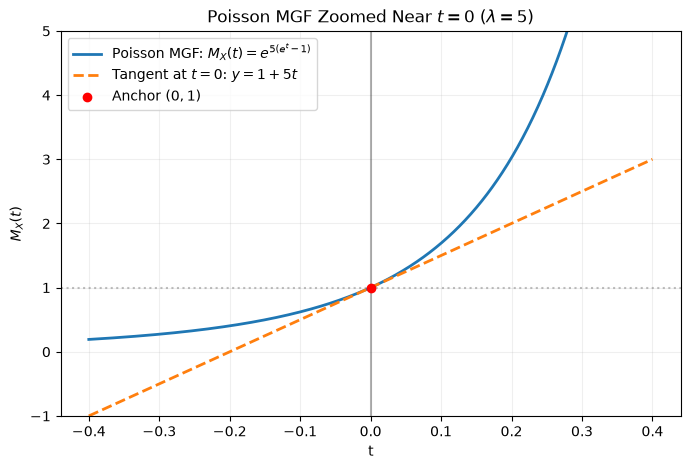

In [1]:
import numpy as np
import matplotlib.pyplot as plt

lam = 5
t = np.linspace(-0.4, 0.4, 1000) # Zoom in closer to t = 0

M = np.exp(lam * (np.exp(t) - 1))
tangent = 1 + lam * t

plt.figure(figsize=(8, 5))
plt.plot(t, M, label=r'Poisson MGF: $M_X(t) = e^{5(e^t - 1)}$', linewidth=2)
plt.plot(t, tangent, '--', label=r'Tangent at $t=0$: $y = 1 + 5t$', linewidth=2)

plt.scatter([0], [1], color='red', zorder=5, label=r'Anchor $(0, 1)$')
plt.axvline(0, color='black', alpha=0.3)
plt.axhline(1, color='gray', linestyle=':', alpha=0.5) # Highlights y = 1

plt.ylim(-1, 5) # Stops the y-axis from blowing up to 5500
plt.xlabel('t')
plt.ylabel(r'$M_X(t)$')
plt.title(r'Poisson MGF Zoomed Near $t = 0$ ($\lambda = 5$)')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

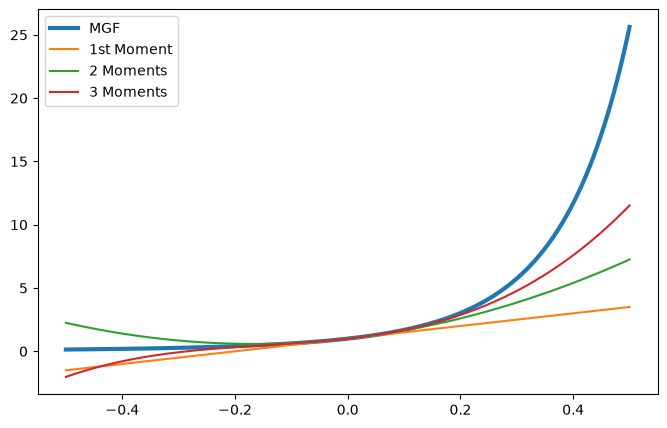

In [30]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

lam = 5

t = np.linspace(-0.5,0.5,500)

mgf = np.exp(lam*(np.exp(t)-1))

EX = lam
EX2 = lam + lam**2
EX3 = lam + 3*lam**2 + lam**3

T1 = 1 + EX*t

T2 = T1 + EX2*t**2/2

T3 = T2 + EX3*t**3/6

plt.figure(figsize=(8,5))
plt.plot(t, mgf, lw=3, label='MGF')
plt.plot(t, T1, label='1st Moment')
plt.plot(t, T2, label='2 Moments')
plt.plot(t, T3, label='3 Moments')

plt.legend()
plt.show()

Every additional moment adds the next term of the Taylor series $\mathbb{E}[X^n]\frac{t^n}{n!}$, which progressively shapes the polynomial so it hugs the true MGF across a wider neighborhood around $t = 0$.


In [4]:
import numpy as np
V = np.linspace(1e-6, 1-1e-6, 1000)
V

array([1.00000000e-06, 1.00199900e-03, 2.00299800e-03, 3.00399700e-03,
       4.00499600e-03, 5.00599499e-03, 6.00699399e-03, 7.00799299e-03,
       8.00899199e-03, 9.00999099e-03, 1.00109900e-02, 1.10119890e-02,
       1.20129880e-02, 1.30139870e-02, 1.40149860e-02, 1.50159850e-02,
       1.60169840e-02, 1.70179830e-02, 1.80189820e-02, 1.90199810e-02,
       2.00209800e-02, 2.10219790e-02, 2.20229780e-02, 2.30239770e-02,
       2.40249760e-02, 2.50259750e-02, 2.60269740e-02, 2.70279730e-02,
       2.80289720e-02, 2.90299710e-02, 3.00309700e-02, 3.10319690e-02,
       3.20329680e-02, 3.30339670e-02, 3.40349660e-02, 3.50359650e-02,
       3.60369640e-02, 3.70379630e-02, 3.80389620e-02, 3.90399610e-02,
       4.00409600e-02, 4.10419590e-02, 4.20429580e-02, 4.30439570e-02,
       4.40449560e-02, 4.50459550e-02, 4.60469540e-02, 4.70479530e-02,
       4.80489520e-02, 4.90499510e-02, 5.00509499e-02, 5.10519489e-02,
       5.20529479e-02, 5.30539469e-02, 5.40549459e-02, 5.50559449e-02,
      

In [5]:
a = 1/2
Ivs = [v*np.log(v/a)+(1-v)*np.log((1-v)/(1-a)) for v in V ]
Ivs


[np.float64(0.6931323650498874),
 np.float64(0.6852261208504928),
 np.float64(0.6787013425675109),
 np.float64(0.6727010516471859),
 np.float64(0.6670417855351978),
 np.float64(0.6616363848874687),
 np.float64(0.6564335067555582),
 np.float64(0.6513992227662513),
 np.float64(0.6465094174969604),
 np.float64(0.6417460593449102),
 np.float64(0.6370951519817253),
 np.float64(0.6325455141048159),
 np.float64(0.628088006755323),
 np.float64(0.6237150200196823),
 np.float64(0.6194201186009868),
 np.float64(0.6151977891615182),
 np.float64(0.6110432553292826),
 np.float64(0.6069523391247735),
 np.float64(0.6029213550992887),
 np.float64(0.5989470280656451),
 np.float64(0.5950264281929895),
 np.float64(0.5911569191123285),
 np.float64(0.5873361159270738),
 np.float64(0.5835618508722529),
 np.float64(0.5798321449561512),
 np.float64(0.5761451843356551),
 np.float64(0.5724993004769013),
 np.float64(0.5688929533721161),
 np.float64(0.5653247172458391),
 np.float64(0.5617932683053952),
 np.float64

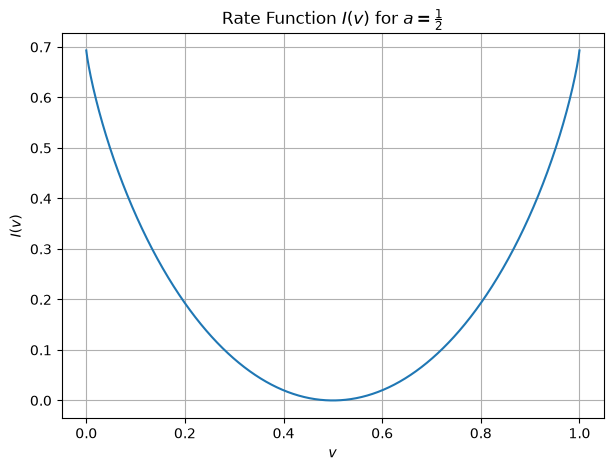

In [9]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7,5))
plt.plot(V, Ivs)

plt.xlabel(r'$v$')
plt.ylabel(r'$I(v)$')
plt.title(r'Rate Function $I(v)$ for $a=\frac{1}{2}$')

plt.grid(True)
plt.show()